In [144]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
from scipy.stats import chi2_contingency
from scipy.stats.contingency import association
import scipy.stats as stats
%matplotlib inline

In [85]:
df = pd.read_csv("amz_uk_price_prediction_dataset.csv")

In [86]:
df.columns

Index(['uid', 'asin', 'title', 'stars', 'reviews', 'price', 'isBestSeller',
       'boughtInLastMonth', 'category'],
      dtype='object')

## Part 1: Analyzing Best-Seller Trends Across Product Categories

In [87]:
# Crosstab Analysis
crosstab_result = pd.crosstab(df['category'], df['isBestSeller'])
crosstab_result

isBestSeller,False,True
category,,
3D Printers,247,1
3D Printing & Scanning,4065,2
Abrasive & Finishing Products,245,5
Action Cameras,1696,1
Adapters,251,3
...,...,...
Wind Instruments,243,7
Window Treatments,234,5
Women,17559,213


In [88]:
proportions = (crosstab_result[True] / crosstab_result.sum(axis=1)).sort_values(ascending=False)
proportions

category
Grocery                             0.058135
Smart Home Security & Lighting      0.057692
Health & Personal Care              0.057686
Mobile Phone Accessories            0.042471
Power & Hand Tools                  0.035339
                                      ...   
CD, Disc & Tape Players             0.000000
General Music-Making Accessories    0.000000
Snowboard Boots                     0.000000
Boxes & Organisers                  0.000000
eBook Readers & Accessories         0.000000
Length: 296, dtype: float64

Are there categories where being a best-seller is more prevalent?

Sí, categorías como Grocery, Smart Home Security & Lighting y Health & Personal Care tienen una mayor prevalencia de productos best-seller en comparación con otras.

In [89]:
# Statistical Tests
chi2_statistic, chi2_p_value, _, _ = chi2_contingency(crosstab_result)
chi2_statistic, chi2_p_value

(36540.20270061387, 0.0)

Sí, hay dependencia entre Category y BestSeller — es decir, la categoría de un producto influye en la probabilidad de que sea un best-seller.

In [90]:
association(crosstab_result, method="cramer")

0.1222829439760564

Tienen una relación débil, aunque la tienen.

In [91]:
crosstab_result_best = crosstab_result.sort_values(by=True,ascending=False).head(10)
crosstab_result_best

isBestSeller,False,True
category,,
Grocery,9008,556
Health & Personal Care,9017,552
Baby,14709,341
Sports & Outdoors,835935,330
Power & Hand Tools,8353,306
Beauty,19010,302
Pet Supplies,9152,285
Arts & Crafts,9319,230
Women,17559,213


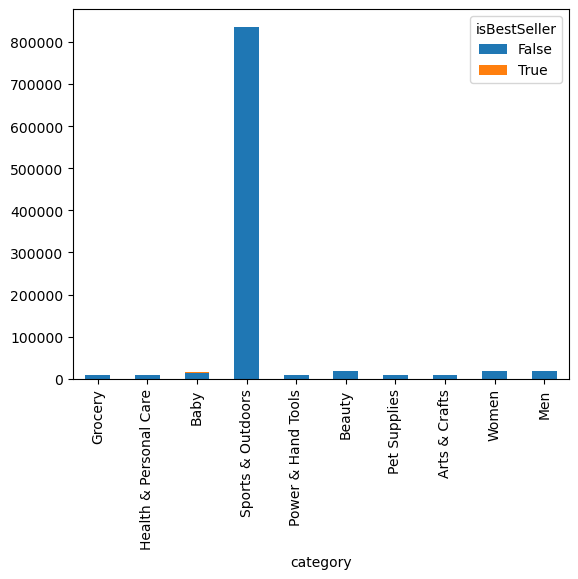

In [92]:
crosstab_result_best.plot(kind="bar", stacked=True)
plt.show()

Aunque se utilizó un gráfico de barras apiladas para mostrar la relación entre categorías y best-seller, la baja proporción de productos exitosos hace que el gráfico esté dominado por la clase False, lo que dificulta ver diferencias claras entre categorías.

## Part 2: Exploring Product Prices and Ratings Across Categories and Brands

In [93]:
# Preliminary Step: Remove outliers in product prices
def tukeys_test_outliers(data):
    Q1 = data.quantile(0.25)
    Q3 = data.quantile(0.75)
    IQR = Q3 - Q1
    
    # Define bounds for the outliers
    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR
    
    # Identify the outliers
    outliers = data[(data < lower_bound) | (data > upper_bound)]
    
    return outliers

In [94]:
outliers_price = tukeys_test_outliers(df['price'])

In [95]:
df_filtered = df[~df["price"].isin(outliers_price)]

In [96]:
print(f"Filas eliminadas: {len(df) - len(df_filtered)}")

Filas eliminadas: 327688


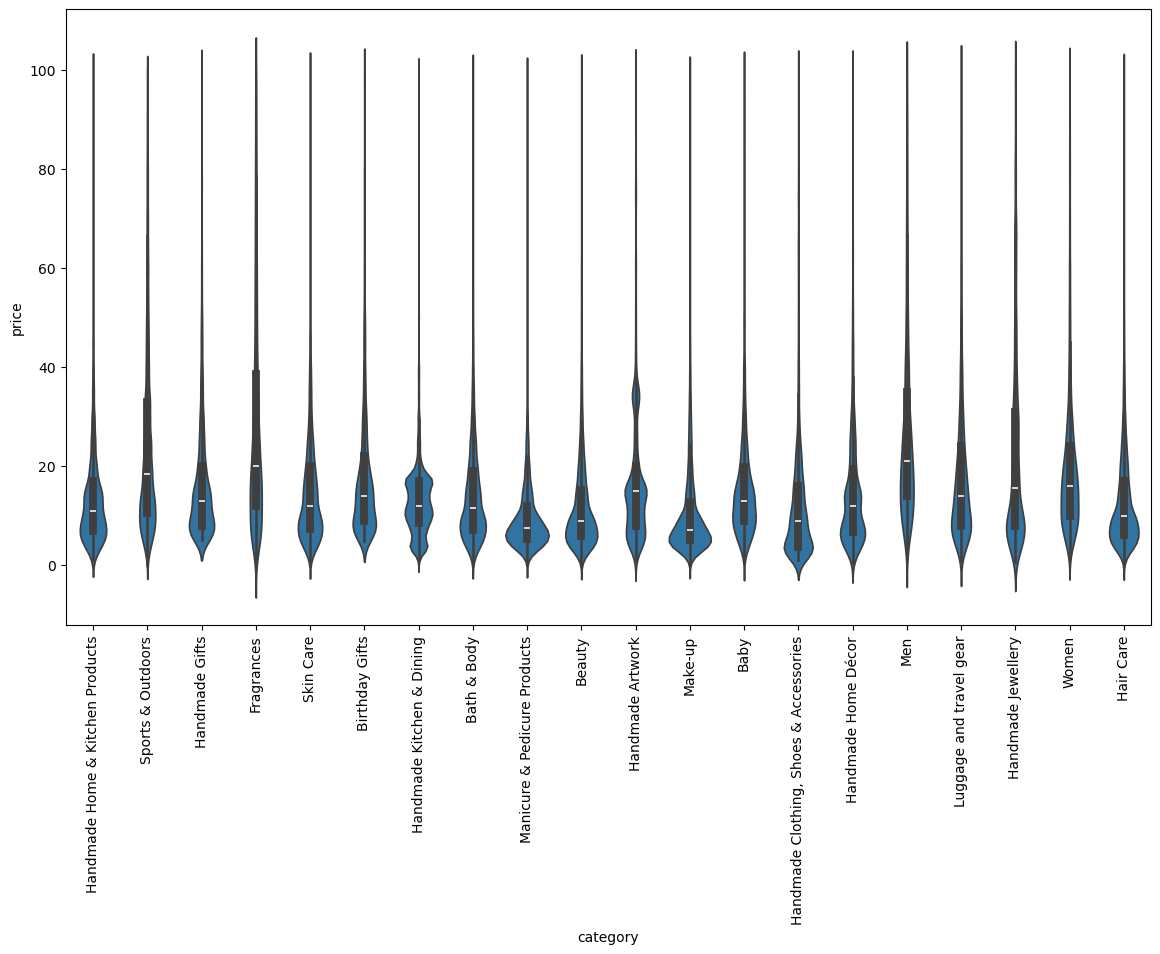

In [100]:
top_categories = df_filtered['category'].value_counts().head(20).index
plt.figure(figsize=(14, 8))
df_top = df_filtered[df_filtered['category'].isin(top_categories)]
sns.violinplot(data=df_top, x='category', y='price')
plt.xticks(rotation=90)
plt.show()

In [103]:
median_price= df_filtered.groupby('category')['price'].median()
median_price.idxmax()

'Desktop PCs'

In [117]:
top_10_categories = df_filtered['category'].value_counts().head(10).index
df_top10 = df_filtered[df_filtered['category'].isin(top_10_categories)]

In [118]:
avg_price_top10 = df_top10.groupby('category')['price'].mean().sort_values(ascending=False)

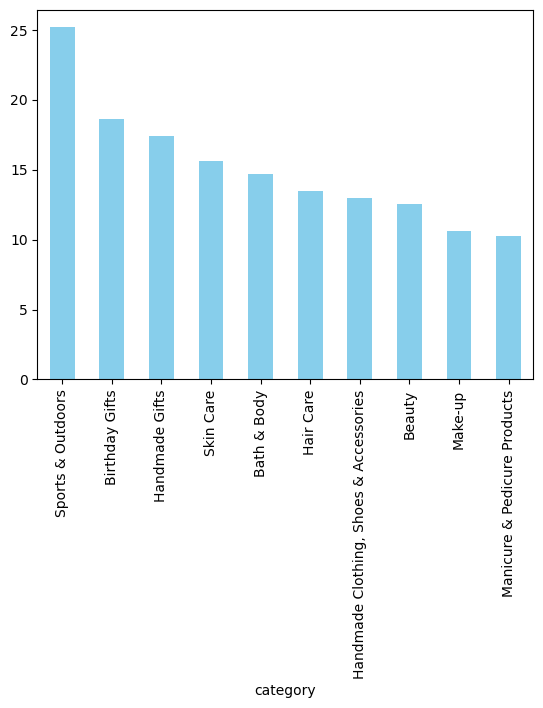

In [119]:
avg_price_top10.plot(kind='bar', color='skyblue')
plt.show()

In [ ]:
avg_price_all = df_filtered.groupby('category')['price'].mean().sort_values(ascending=False).head(1)
avg_price_all

category
Motherboards    68.772432
Name: price, dtype: float64

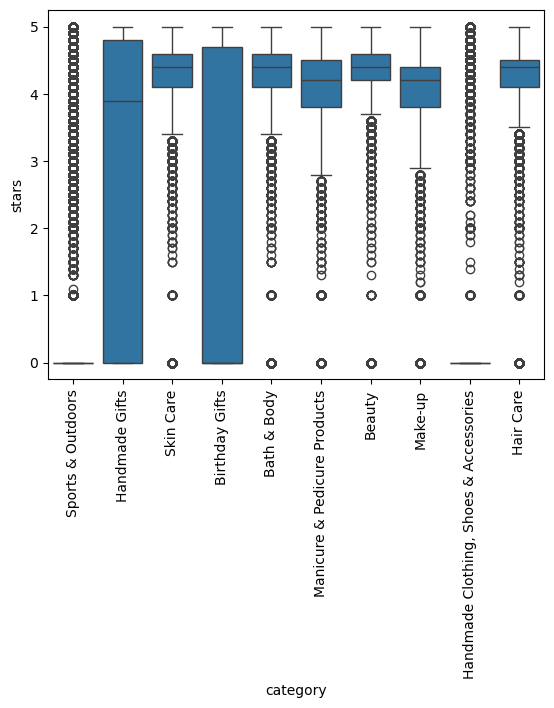

In [127]:
sns.boxplot(data=df_top10, x='category', y='stars')
plt.xticks(rotation=90)
plt.show()

In [130]:
median_ratings = df_filtered.groupby('category')['stars'].median().sort_values(ascending=False).head(1)
median_ratings

category
Computer Memory    4.7
Name: stars, dtype: float64

## Part 3: Investigating the Interplay Between Product Prices and Ratings

In [138]:
correlation = df_filtered['price'].corr(df['stars'])
correlation

-0.0776729987818137

No hay una correlación significativa entre el precio del producto y su rating.
Es decir, los productos más caros no tienden a tener mejores ni peores valoraciones de forma consistente.

In [134]:
correlation = df['price'].corr(df['stars'], method='spearman')
correlation

-0.1331642546243379

Los productos más caros no tienden a recibir mejores ni peores ratings de manera consistente, ni lineal ni monotónicamente.

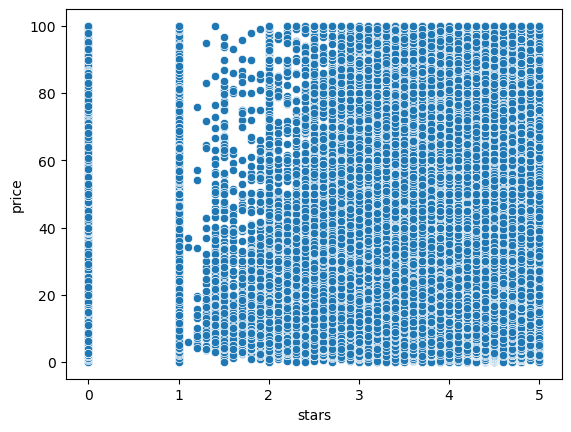

In [137]:
sns.scatterplot(data=df_filtered, x='stars', y='price')
plt.show()

In [150]:
numerical = df_filtered.select_dtypes(include=['number'])
potential_categorical_from_numerical = df_filtered.select_dtypes("number").loc[:, df_filtered.select_dtypes("number").nunique() < 10]

In [151]:
numerical = df_filtered.select_dtypes("number").drop(columns=potential_categorical_from_numerical.columns)

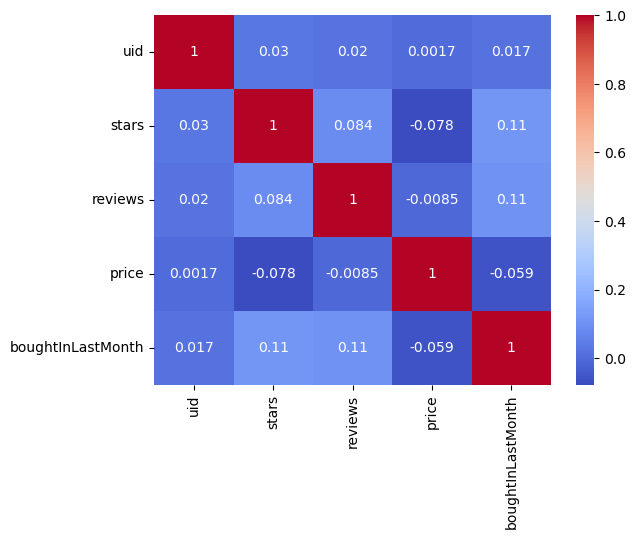

In [154]:
correlation_matrix = numerical.corr()
sns.heatmap(correlation_matrix, annot=True, cmap='coolwarm')
plt.show()

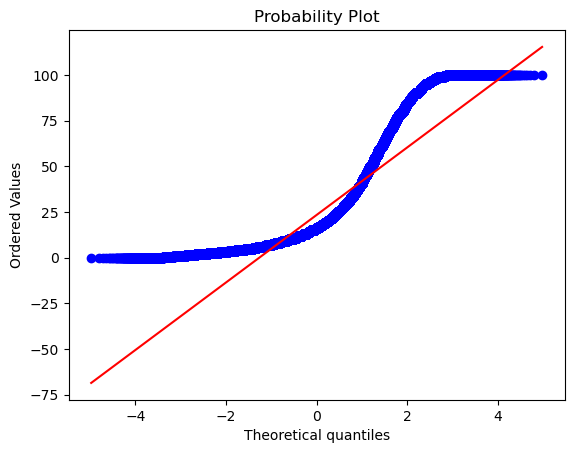

In [157]:
stats.probplot(df_filtered['price'].dropna(), dist="norm", plot=plt)
plt.show()